# Regresja logistyczna – klasyfikacja binarna

**Plan notatnika:**
1. Od regresji liniowej do klasyfikacji
2. Funkcja sigmoidalna
3. Model regresji logistycznej
4. Pierwszy model w scikit-learn
5. Próg odcięcia
6. Szanse (odds) i log-odds – jak czytać współczynniki
7. Więcej niż jedna cecha
8. Jak model się uczy – metoda największej wiarygodności
9. Statystyczny opis modelu – `statsmodels`
10. Założenia modelu
11. Podsumowanie

## 1. Od regresji liniowej do klasyfikacji

Mimo nazwy **regresja logistyczna jest modelem do klasyfikacji**. Najczęściej używamy jej, gdy wynik ma tylko dwie wartości (0 lub 1), np.:
- spam / nie spam,
- klient spłaci kredyt / nie spłaci,
- transakcja jest oszustwem / nie jest,
- pacjent jest chory / zdrowy.

Zamiast samej klasy model zwraca **prawdopodobieństwo klasy 1**, a klasę wybieramy na jego podstawie.

**Przykład, na którym będziemy pracować:** zbiór demonstracyjny, w którym na podstawie wieku (`age`) i faktu palenia (`smoke`) przewidujemy, czy dana osoba **nie przeżyje kolejnych 10 lat** (`target = 1`) czy przeżyje (`target = 0`). To uproszczone dane, służące tylko do nauki.

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression

df = pd.DataFrame({
    'age':    [20, 21, 22, 23, 24, 35, 26, 57, 68, 75, 83, 80, 60, 78],
    'smoke':  [0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0],
    'target': [0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1],
})
df

,age,smoke,target
0,20,0,0
1,21,1,1
2,22,0,0
3,23,0,0
4,24,0,0
5,35,0,0
6,26,0,0
7,57,0,0
8,68,1,1
9,75,1,1


- `age` – wiek w latach,
- `smoke` – czy osoba pali (1 = tak, 0 = nie),
- `target` – **zmienna celu**: 1 = nie przeżyje kolejnych 10 lat, 0 = przeżyje.

**A może zwykła regresja liniowa?** Spróbujmy dopasować prostą do zmiennej 0/1:

In [17]:
lin = LinearRegression().fit(df[['age']], df['target'])

nowe_wieki = pd.DataFrame({'age': [10, 90]})
print('Przewidywania regresji liniowej dla 10 i 90 lat:', lin.predict(nowe_wieki).round(3))

Przewidywania regresji liniowej dla 10 i 90 lat: [-0.092  1.004]


Dla 10 lat wynik jest **ujemny**, a dla 90 lat **większy od 1**. Takich wartości nie da się zinterpretować jako prawdopodobieństwa. Prosta wychodzi poza przedział $[0, 1]$, co dobrze widać na rysunku:

![Regresja liniowa dla zmiennej 0/1](../obrazki/3.2_regresja_liniowa_problem.png)

## 2. Funkcja sigmoidalna

Potrzebujemy funkcji, która **dowolną liczbę** zamieni na wartość z przedziału $(0, 1)$. Taką funkcją jest **sigmoida** (funkcja logistyczna):

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

- dla bardzo dużych $z$ wynik zbliża się do 1,
- dla bardzo małych $z$ (ujemnych) zbliża się do 0,
- dla $z = 0$ wynik wynosi dokładnie 0,5.

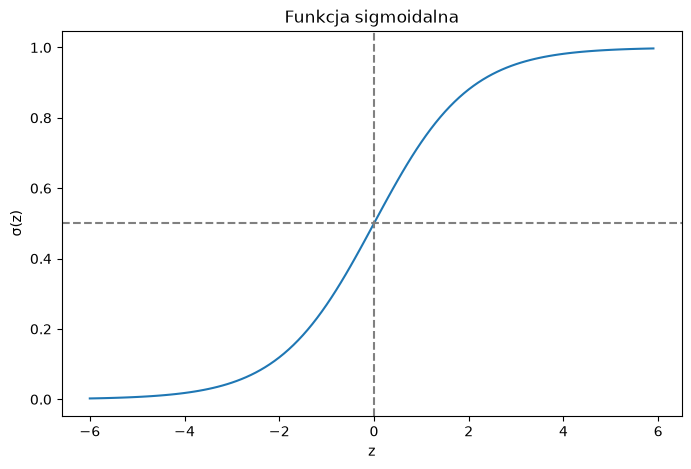

In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.arange(-6, 6, 0.1)

plt.figure(figsize=(8, 5))
plt.plot(z, sigmoid(z))
plt.axhline(0.5, color='gray', linestyle='--')
plt.axvline(0, color='gray', linestyle='--')
plt.title('Funkcja sigmoidalna')
plt.xlabel('z')
plt.ylabel('σ(z)')
plt.show()

## 3. Model regresji logistycznej

Model działa w dwóch krokach:
1. liczy **wynik liniowy** – dokładnie tak jak regresja liniowa: $z = w_0 + w_1 x_1 + \dots + w_n x_n$,
2. przepuszcza go przez sigmoidę, otrzymując **prawdopodobieństwo klasy 1**:

$$P(y=1 \mid x) = \sigma(z) = \frac{1}{1 + e^{-(w_0 + w_1 x_1 + \dots + w_n x_n)}}$$

Dla jednej cechy (wiek) wzór wygląda tak:

$$P(\text{nie przeżyje} \mid \text{wiek}) = \frac{1}{1 + e^{-(w_0 + w_1 \cdot \text{wiek})}}$$

Parametry $w_0, w_1$ model dobiera na podstawie danych. Dzięki sigmoidzie krzywa ma kształt litery **S** i nigdy nie wychodzi poza przedział $(0, 1)$:

![Regresja liniowa i logistyczna](../obrazki/3.2_liniowa_vs_logistyczna.png)

## 4. Pierwszy model w scikit-learn

Budujemy model na jednej cesze – wieku. Użyjemy `DataFrame` zarówno do uczenia, jak i do predykcji, aby nazwy cech się zgadzały.

In [4]:
X = df[['age']]
y = df['target']

model = LogisticRegression()
model.fit(X, y)

w0 = model.intercept_[0]
w1 = model.coef_[0][0]
print(f'w0 (intercept_) = {w0:.3f}')
print(f'w1 (coef_)      = {w1:.3f}')

w0 (intercept_) = -4.001
w1 (coef_)      = 0.073


Teraz sprawdźmy, co model przewiduje dla osoby w wieku 30 lat:
- `predict_proba` zwraca **dwie kolumny**: prawdopodobieństwo klasy 0 i klasy 1,
- `predict` zwraca gotową klasę (0 lub 1).

In [5]:
osoba = pd.DataFrame({'age': [30]})

print('predict_proba [P(klasa 0), P(klasa 1)]:', model.predict_proba(osoba).round(3))
print('predict (klasa):                       ', model.predict(osoba))

predict_proba [P(klasa 0), P(klasa 1)]: [[0.859 0.141]]
predict (klasa):                        [0]


Sprawdźmy, czy rozumiemy wzór: podstawimy wyuczone $w_0, w_1$ do sigmoidy i porównamy z wynikiem `predict_proba`.

In [ ]:
z_30 = w0 + w1 * 30
p_30 = 1 / (1 + np.exp(-z_30))

print(f'wynik liniowy z = {z_30:.3f}')
print(f'P(klasa 1) ze wzoru = {p_30:.3f}')
print(f'P(klasa 1) z modelu = {model.predict_proba(osoba)[0, 1]:.3f}')

Zobaczmy cały model na wykresie i porównajmy go z prostą regresji liniowej:

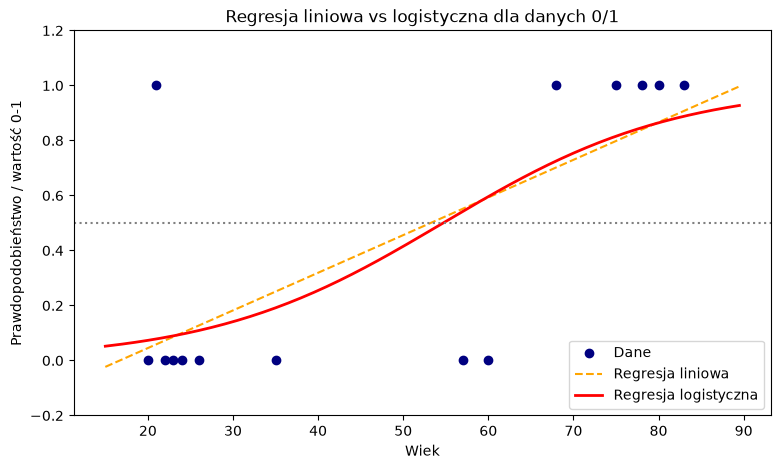

In [6]:
wieki = pd.DataFrame({'age': np.arange(15, 90, 0.5)})

plt.figure(figsize=(9, 5))
plt.scatter(df['age'], df['target'], color='navy', zorder=3, label='Dane')
plt.plot(wieki['age'], lin.predict(wieki), color='orange', linestyle='--', label='Regresja liniowa')
plt.plot(wieki['age'], model.predict_proba(wieki)[:, 1], color='red', linewidth=2, label='Regresja logistyczna')
plt.axhline(0.5, color='gray', linestyle=':')
plt.ylim(-0.2, 1.2)
plt.xlabel('Wiek')
plt.ylabel('Prawdopodobieństwo / wartość 0-1')
plt.title('Regresja liniowa vs logistyczna dla danych 0/1')
plt.legend()
plt.show()

## 5. Próg odcięcia

Model zwraca prawdopodobieństwo, ale na końcu potrzebujemy **decyzji** (klasa 0 czy 1). Służy do tego **próg odcięcia** (*threshold*):
- jeśli $p \geq$ próg → klasa 1,
- jeśli $p <$ próg → klasa 0.

Domyślny próg to 0,5 (tak działa `predict`), ale **nie zawsze jest najlepszy**:
- chcemy wykryć jak najwięcej przypadków klasy 1 (np. choroba) → **obniżamy** próg (więcej alarmów, w tym fałszywych),
- chcemy ograniczyć fałszywe alarmy (np. blokada konta) → **podnosimy** próg.

![Wpływ progu odcięcia](../obrazki/3.2_prog_odciecia.png)

In [7]:
proba = model.predict_proba(X)[:, 1]   # P(klasa 1) dla wszystkich osób ze zbioru

wyniki = []
for prog in [0.05, 0.5, 0.8]:
    klasa = (proba >= prog).astype(int)
    wyniki.append({
        'próg': prog,
        'accuracy': (klasa == y).mean(),
        'wykryte klasy 1': int(klasa[y == 1].sum()),
        'wszystkie klasy 1': int(y.sum()),
        'fałszywe alarmy': int(klasa[y == 0].sum()),
    })

pd.DataFrame(wyniki).set_index('próg').round(2)

,accuracy,wykryte klasy 1,wszystkie klasy 1,fałszywe alarmy
próg,,,,
0.05,0.43,6,6,8
0.50,0.79,5,6,2
0.80,0.86,4,6,0


Im niższy próg, tym więcej wykrytych przypadków klasy 1, ale też więcej fałszywych alarmów. Dokładne metryki (precision, recall) poznamy w następnym notatniku.

## 6. Szanse (odds) i log-odds – jak czytać współczynniki

Współczynniki regresji logistycznej **nie mówią wprost, o ile zmienia się prawdopodobieństwo**. Opisują zmianę **logarytmu szans** (*log-odds*).

**Szansa** (*odds*) to stosunek prawdopodobieństwa zdarzenia do prawdopodobieństwa jego braku:

$$\text{odds} = \frac{p}{1-p} \qquad \text{log-odds} = \ln\left(\frac{p}{1-p}\right)$$

Przykład: $p = 0{,}8$ → szansa $= 0{,}8 / 0{,}2 = 4$, czyli „4 do 1”.

Wynik liniowy modelu to właśnie log-odds:

$$\ln\left(\frac{p}{1-p}\right) = w_0 + w_1 \cdot \text{wiek}$$

Dlatego:
- $w_1 > 0$ – wzrost cechy **zwiększa** szansę klasy 1, $w_1 < 0$ – **zmniejsza**,
- wzrost cechy o 1 zwiększa log-odds o $w_1$, a **szanse mnożymy przez** $e^{w_1}$ (tzw. **iloraz szans**, *odds ratio*),
- zależność jest liniowa w skali log-odds, ale **nie** w skali prawdopodobieństwa (krzywa jest S-kształtna).

In [8]:
tabela = pd.DataFrame({'age': [30, 40, 50, 60, 70]})
tabela['log-odds (z)'] = w0 + w1 * tabela['age']
tabela['prawdopodobieństwo p'] = 1 / (1 + np.exp(-tabela['log-odds (z)']))
tabela['odds = p/(1-p)'] = tabela['prawdopodobieństwo p'] / (1 - tabela['prawdopodobieństwo p'])
tabela.round(3)

,age,log-odds (z),prawdopodobieństwo p,odds = p/(1-p)
0,30,-1.806,0.141,0.164
1,40,-1.075,0.255,0.341
2,50,-0.343,0.415,0.710
3,60,0.389,0.596,1.475
4,70,1.120,0.754,3.066


In [9]:
iloraz_szans = np.exp(w1)
print(f'e^w1 = {iloraz_szans:.3f}  -> każdy kolejny rok życia mnoży szanse przez {iloraz_szans:.3f}')

# sprawdzenie: iloraz szans dla 41 i 40 lat powinien być taki sam
odds = lambda wiek: np.exp(w0 + w1 * wiek)
print(f'odds(41) / odds(40) = {odds(41) / odds(40):.3f}')

e^w1 = 1.076  -> każdy kolejny rok życia mnoży szanse przez 1.076
odds(41) / odds(40) = 1.076


Szanse rosną z wiekiem o stały **procent** (tu około 8% na rok), natomiast prawdopodobieństwo rośnie w sposób nieliniowy – najszybciej w środku krzywej, wolniej na jej końcach.

## 7. Więcej niż jedna cecha

Do modelu dodajemy cechę `smoke`. Wzór rozszerza się o kolejny składnik:

$$P(y=1 \mid x) = \frac{1}{1 + e^{-(w_0 + w_1 \cdot \text{wiek} + w_2 \cdot \text{smoke})}}$$

In [10]:
X2 = df[['age', 'smoke']]

model2 = LogisticRegression()
model2.fit(X2, y)

print('Współczynniki:', dict(zip(X2.columns, model2.coef_[0].round(3))))
print('Wyraz wolny:  ', model2.intercept_.round(3))
print('Ilorazy szans:', dict(zip(X2.columns, np.exp(model2.coef_[0]).round(3))))

Współczynniki: {'age': np.float64(0.065), 'smoke': np.float64(0.77)}
Wyraz wolny:   [-3.911]
Ilorazy szans: {'age': np.float64(1.067), 'smoke': np.float64(2.159)}


In [11]:
dwie_osoby = pd.DataFrame({'age': [50, 50], 'smoke': [0, 1]})
dwie_osoby['P(klasa 1)'] = model2.predict_proba(dwie_osoby)[:, 1].round(3)
dwie_osoby

,age,smoke,P(klasa 1)
0,50,0,0.336
1,50,1,0.523


Dwie osoby w tym samym wieku różnią się tylko paleniem – model przypisuje im różne prawdopodobieństwa. Współczynnik przy `smoke` jest dodatni, więc palenie **zwiększa** szansę klasy 1 (przy ustalonym wieku).

*Uwaga:* zbiór ma tylko 14 wierszy, więc te liczby traktujemy wyłącznie jako ilustrację. W rzeczywistych projektach potrzeba znacznie więcej danych.

## 8. Jak model się uczy – metoda największej wiarygodności

W regresji liniowej minimalizowaliśmy błąd średniokwadratowy. W regresji logistycznej dobieramy parametry tak, aby **zaobserwowane etykiety były jak najbardziej prawdopodobne**. To **metoda największej wiarygodności** (*Maximum Likelihood Estimation*, MLE).

Intuicyjnie: każdy zestaw parametrów to inna krzywa S. Dla każdej z nich sprawdzamy, jak bardzo „zgadza się” z danymi, i wybieramy najlepszą.

![Jedna z możliwych krzywych](../obrazki/3.2_mle_kandydat.png)

![Wiele możliwych krzywych](../obrazki/3.2_mle_kandydaci.png)

![Krzywa o największej wiarygodności](../obrazki/3.2_mle_najlepszy.png)

**Jak to zapisać?** Dla jednej obserwacji z etykietą $y_i \in \{0, 1\}$ i przewidzianym prawdopodobieństwem $p_i$ wiarygodność wynosi:

$$p_i^{\,y_i} \cdot (1 - p_i)^{\,1 - y_i}$$

(dla $y_i = 1$ jest to $p_i$, dla $y_i = 0$ jest to $1 - p_i$). Wiarygodność całego zbioru to iloczyn po wszystkich obserwacjach. W praktyce zamiast iloczynu maksymalizujemy jego logarytm, a właściwie minimalizujemy jego przeciwieństwo uśrednione po danych, czyli **log-loss** (*binary cross-entropy*):

$$\text{log-loss} = -\frac{1}{m}\sum_{i=1}^{m}\Big[y_i \ln p_i + (1 - y_i)\ln(1 - p_i)\Big]$$

Im mniejszy log-loss, tym lepsze dopasowanie. Sprawdźmy to dla kilku zestawów parametrów:

In [12]:
from sklearn.metrics import log_loss

def log_loss_reczny(w0, w1):
    p = 1 / (1 + np.exp(-(w0 + w1 * df['age'])))
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

print(f'Parametry z modelu (w0={w0:.2f}, w1={w1:.3f}): {log_loss_reczny(w0, w1):.3f}')
print(f'Inne parametry     (w0=-2,    w1=0.02):  {log_loss_reczny(-2, 0.02):.3f}')
print(f'Inne parametry     (w0=-8,    w1=0.15):  {log_loss_reczny(-8, 0.15):.3f}')
print(f'sklearn.log_loss dla modelu:            {log_loss(y, model.predict_proba(X)):.3f}')

Parametry z modelu (w0=-4.00, w1=0.073): 0.420
Inne parametry     (w0=-2,    w1=0.02):  0.605
Inne parametry     (w0=-8,    w1=0.15):  0.535
sklearn.log_loss dla modelu:            0.420


Parametry wyuczone przez model mają najmniejszy log-loss. Ręczny wynik zgadza się z funkcją `log_loss` ze scikit-learn.

**Jak algorytm szuka najlepszych parametrów?** Nie istnieje tu prosty wzór jak w równaniu normalnym, więc stosuje się metody iteracyjne oparte na **gradiencie** (jak spadek wzdłuż gradientu z rozdziału 3.1). W `LogisticRegression` domyślnie działa algorytm `lbfgs`, a my nie musimy go implementować.

**Regularyzacja:** `LogisticRegression` domyślnie dodaje karę za zbyt duże współczynniki (parametr `C=1.0`; mniejsze `C` = silniejsza kara). Dlatego współczynniki ze scikit-learn mogą się nieco różnić od wyników „czystej” MLE z biblioteki `statsmodels`. Do regularyzacji wrócimy w rozdziale o niedouczeniu i przeuczeniu.

## 9. Statystyczny opis modelu – `statsmodels`

Biblioteka `statsmodels` dopasowuje ten sam model, ale zwraca **pełne podsumowanie statystyczne** (błędy standardowe, p-value, przedziały ufności). Jest przydatna, gdy chcemy **interpretować** model, a nie tylko przewidywać. Do macierzy cech trzeba dodać stałą (`add_constant`), która odpowiada wyrazowi wolnemu $w_0$.

In [13]:
import statsmodels.api as sm

X_sm = sm.add_constant(df[['age']])
logit = sm.Logit(y, X_sm)
wynik = logit.fit()

print(wynik.summary())

Optimization terminated successfully.
         Current function value: 0.419705
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                 target   No. Observations:                   14
Model:                          Logit   Df Residuals:                       12
Method:                           MLE   Df Model:                            1
Date:                Sun, 01 Nov 2026   Pseudo R-squ.:                  0.3854
Time:                        10:54:46   Log-Likelihood:                -5.8759
converged:                       True   LL-Null:                       -9.5607
Covariance Type:            nonrobust   LLR p-value:                  0.006633
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -4.0057      1.956     -2.048      0.041      -7.840      -0.172
age            0.0733      0.

**Jak czytać tabelę ze współczynnikami:**

- `coef` – estymowany współczynnik ($w_0$ to `const`, $w_1$ to `age`); zmiana log-odds,
- `std err` – błąd standardowy; im mniejszy, tym stabilniejsze oszacowanie,
- `z` – statystyka testowa $z = \text{coef} / \text{std err}$; im większa wartość bezwzględna, tym silniejszy sygnał, że współczynnik jest różny od zera,
- kolumna z p-value (nagłówek `P>|z|`) – prawdopodobieństwo takiego wyniku, gdyby współczynnik w rzeczywistości był równy 0; zwykle uznajemy za istotne wartości poniżej 0,05,
- `[0.025 0.975]` – 95% przedział ufności współczynnika; jeśli nie obejmuje zera, współczynnik zwykle uznajemy za istotny.

Uwaga: p-value to kryterium pomocnicze – zawsze interpretujemy je razem z kontekstem i wielkością efektu. Przy tak małym zbiorze (14 obserwacji) wnioski statystyczne są bardzo niepewne.

Ilorazy szans i ich przedziały ufności otrzymujemy, przekształcając wyniki funkcją $e^x$:

In [14]:
iloraz = pd.DataFrame({
    'iloraz szans': np.exp(wynik.params),
    'dolna granica 95%': np.exp(wynik.conf_int()[0]),
    'górna granica 95%': np.exp(wynik.conf_int()[1]),
})
iloraz.round(3)

,iloraz szans,dolna granica 95%,górna granica 95%
const,0.018,0.000,0.842
age,1.076,1.007,1.150


Porównajmy jeszcze współczynniki z `statsmodels` i ze scikit-learn. Po wyłączeniu regularyzacji (bardzo duże `C`) powinny być prawie takie same:

In [15]:
model_bez_reg = LogisticRegression(C=1e6).fit(X, y)

porownanie = pd.DataFrame({
    'statsmodels': [wynik.params['const'], wynik.params['age']],
    'sklearn (C=1)': [w0, w1],
    'sklearn (C=1e6)': [model_bez_reg.intercept_[0], model_bez_reg.coef_[0][0]],
}, index=['w0', 'w1'])
porownanie.round(3)

,statsmodels,sklearn (C=1),sklearn (C=1e6)
w0,-4.006,-4.001,-4.006
w1,0.073,0.073,0.073


## 10. Założenia modelu

Regresja logistyczna działa dobrze, gdy (praktyczne reguły):
1. zmienna celu jest **binarna** (0/1),
2. obserwacje są **niezależne** od siebie,
3. zależność między cechami a **log-odds** jest w przybliżeniu liniowa,
4. cechy nie są **silnie skorelowane** ze sobą (współliniowość utrudnia interpretację współczynników),
5. w danych jest **wystarczająco dużo** przypadków obu klas,
6. cechy kategoryczne są poprawnie zakodowane (np. `OneHotEncoder`), a cechy liczbowe warto **przeskalować** – szczególnie przy regularyzacji.

Nie są to sztywne warunki „zero-jedynkowe”, ale dobre praktyki poprawiające stabilność modelu i interpretację wyników.

## 11. Podsumowanie

**Co przewiduje model?** Prawdopodobieństwo klasy 1:

$$P(y=1 \mid x) = \frac{1}{1 + e^{-(w_0 + w_1 x_1 + \dots + w_n x_n)}}$$

Klasę wyznacza **próg odcięcia** (domyślnie 0,5).

**Klasyfikacja a regresja liniowa:**
- regresja liniowa przewiduje wartość liczbową (cena, sprzedaż),
- regresja logistyczna przewiduje klasę lub prawdopodobieństwo klasy.

**Jak czytać współczynniki?**
- znak współczynnika wskazuje kierunek wpływu cechy,
- $e^{w_i}$ to iloraz szans: o ile razy zmieniają się szanse klasy 1, gdy cecha rośnie o 1 (przy pozostałych cechach bez zmian).

**Jak się uczy?** Przez minimalizację log-loss (metoda największej wiarygodności).

**Co zapamiętać:**
1. Regresja logistyczna to podstawowy model klasyfikacji binarnej i dobry **punkt odniesienia** (baseline).
2. Zwraca prawdopodobieństwo – o klasie decyduje próg, który dobieramy do problemu biznesowego.
3. Współczynniki są liniowe w skali log-odds, a nie prawdopodobieństwa.
4. Sama accuracy nie wystarcza do oceny klasyfikatora – o metrykach jest następny notatnik.